In [ ]:
# conda env 'at3d_pure_k9'
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent
INTERIM_DATA = PROJECT_ROOT / 'data' / 'interim'

import sys
sys.path.append(str(PROJECT_ROOT))

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from src.utils.util import load_sensor_dict
from src.utils.util import save_sensor_dict

In [ ]:
## INPUT
lut_file = PROJECT_ROOT / 'NK1990_1D_Retrieval' / 'LUT_V04.nc'
obs_file = INTERIM_DATA / 'AT3D_OBS_CAMP2Ex_RF17_default.nc'
rte_grid_file = INTERIM_DATA / 'RTG_default.nc'

## OUTPUT
out_file = INTERIM_DATA / 'TAU1D_LUT_V04_AT3D_OBS_CAMP2Ex_RF17_default.nc'

In [3]:
rte_grid = xr.load_dataset(rte_grid_file)
obs = load_sensor_dict(obs_file)
LUT = xr.load_dataset(lut_file)
assert np.all(np.diff(LUT.brf.data) > 0), "LUT BRF not monotonic"

In [ ]:
cam = obs['MISR']['sensor_list'][4]
measured_brf = (cam.I.copy(deep=True)*np.pi/cam.mu0).data
measured_tau = np.zeros(measured_brf.shape)
for i, m_brf in enumerate(measured_brf):
    measured_tau[i] = LUT.sel(brf=m_brf, method='nearest').tau.data
measured_tau[measured_tau <= np.min(LUT.tau.data)] = 0
cam['tau'] = (['nrays'], measured_tau)
save_sensor_dict(out_file, obs)

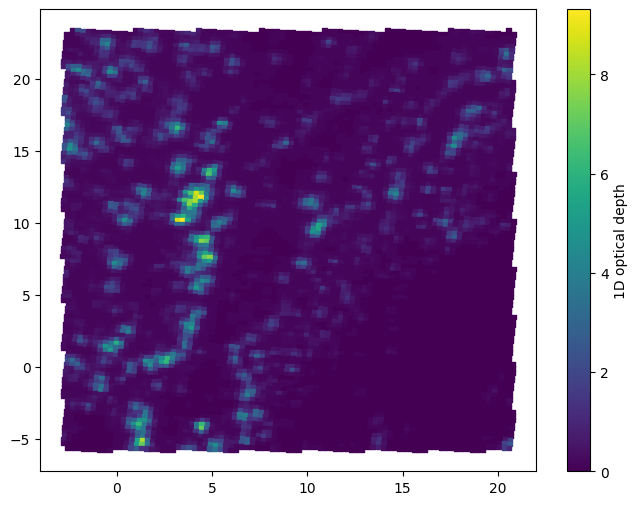

In [7]:
f, ax = plt.subplots(1, 1, figsize=(8,6))
# c = ax.scatter(cam.ray_x, cam.ray_y, c=cam.tau, marker='s', s=10, norm=colors.LogNorm(vmin=0.1, vmax=10))
c = ax.scatter(cam.ray_x, cam.ray_y, c=cam.tau, marker='s', s=10, vmin=0.0, vmax=None)
plt.colorbar(c, label='1D optical depth')